# 02 · Recreación del análisis y comparación con el artículo

Pasos 5 y 6 de la guía. Se aplica a los datos simulados el **mismo procedimiento** de Mihaljević & Santamaría (2021):

| Etapa | Artículo | Recreación |
|---|---|---|
| Bloqueo | apellido + 1.ª inicial | igual (`src/names.py`) |
| Variables por par | Tabla 2 | 26 variables equivalentes (`src/features.py`) |
| Partición | 98 bloques entrenamiento / 39 prueba | igual, por bloque |
| Clasificadores | Decision Tree, Random Forest, Hist-GBDT | igual (scikit-learn) |
| Proporción de clases | original, {0:1,1:1}, {0:2,1:1}, {0:1,1:2}, {0:5,1:1} | igual, por submuestreo |
| Hiperparámetros | búsqueda aleatoria, 200 iteraciones, CV 5 | búsqueda aleatoria, 10 iteraciones, `GroupKFold(5)` por bloque |
| Función objetivo | accuracy y average precision → 30 modelos | igual → 30 modelos |
| Perfiles | grafo ponderado + label propagation asíncrono | igual (NetworkX) |
| Evaluación | BCubed micro / macro, línea base de Milojević | igual |
| Interpretación | LIME | implementación propia del principio de LIME (`src/explain.py`) |

In [1]:
import json
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as C, explain as EX, features as F, metrics as ME, models as M
from src import pipeline as PP, plots as PL

PL.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

df = pd.read_csv(C.DATA / "simulated_authorships.csv", keep_default_na=False)
pairs = F.load_or_build_pairs(df, "base")
train = pairs[pairs.subset == "train"].reset_index(drop=True)
test = pairs[pairs.subset != "train"].reset_index(drop=True)
print(f"entrenamiento: {len(train):,} pares ({train.y.mean():.1%} clase 1) · "
      f"prueba: {len(test):,} pares ({test.y.mean():.1%} clase 1)")

entrenamiento: 188,972 pares (64.9% clase 1) · prueba: 1,435,640 pares (48.2% clase 1)


## 1. Entrenamiento de los 30 modelos
Para cada algoritmo y proporción de clases se hace **una** búsqueda aleatoria que registra a la vez accuracy y average precision; con los mejores hiperparámetros de cada métrica se entrena un modelo (3 × 5 × 2 = 30).

In [2]:
t0 = time.time()
trained = M.train_all(train, F.FEATURES)
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")
hp = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in trained])
hp["params"] = hp.params.apply(lambda p: json.dumps({k: (float(v) if isinstance(v, float) else v) for k, v in p.items()}))
hp.to_csv(C.RESULTS / "02_hiperparametros_30_modelos.csv", index=False)
hp[["algorithm", "ratio", "scoring", "cv_score", "n_train", "params"]].head(10)

Decision Tree  original   n= 188972    2.6s


Decision Tree  {0:1,1:1}  n= 132592    0.5s


Decision Tree  {0:2,1:1}  n=  99444    0.5s


Decision Tree  {0:1,1:2}  n= 184014    0.5s


Decision Tree  {0:5,1:1}  n=  79555    0.4s


...

Hist-GBDT      {0:1,1:1}  n= 132592    5.2s


Hist-GBDT      {0:2,1:1}  n=  99444    8.3s


Hist-GBDT      {0:1,1:2}  n= 184014    9.2s


Hist-GBDT      {0:5,1:1}  n=  79555    6.7s
Tiempo total: 1.4 min


,algorithm,ratio,scoring,cv_score,n_train,params
0,Decision Tree,original,accuracy,0.900178,188972,"{""min_samples_leaf"": 1, ""max_features"": ""sqrt""..."
1,Decision Tree,original,average precision,0.949682,188972,"{""min_samples_leaf"": 50, ""max_features"": ""sqrt..."
2,Decision Tree,"{0:1,1:1}",accuracy,0.885585,132592,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
3,Decision Tree,"{0:1,1:1}",average precision,0.907562,132592,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
4,Decision Tree,"{0:2,1:1}",accuracy,0.894031,99444,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
5,Decision Tree,"{0:2,1:1}",average precision,0.855160,99444,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
6,Decision Tree,"{0:1,1:2}",accuracy,0.898551,184014,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
7,Decision Tree,"{0:1,1:2}",average precision,0.961105,184014,"{""min_samples_leaf"": 10, ""max_features"": ""sqrt..."
8,Decision Tree,"{0:5,1:1}",accuracy,0.871021,79555,"{""min_samples_leaf"": 1, ""max_features"": ""sqrt""..."
9,Decision Tree,"{0:5,1:1}",average precision,0.735330,79555,"{""min_samples_leaf"": 1, ""max_features"": ""sqrt""..."


## 2. Perfiles de autor y métricas BCubed
Cada modelo predice la probabilidad de "mismo autor" para todos los pares de prueba; se arma el grafo (arista si p ≥ 0,5, peso = p), se detectan comunidades con label propagation y se comparan con los autores reales.

In [3]:
t0 = time.time()
evaluated = []
for r in trained:
    ev = PP.evaluate_model(r["model"], df, test, F.FEATURES)
    evaluated.append({**{k: r[k] for k in ("algorithm", "ratio", "scoring")}, **ev, "model": r["model"]})
rule = PP.evaluate_rule(df)
print(f"Evaluación: {(time.time() - t0) / 60:.1f} min")
table = PP.long_table(evaluated)
table.to_csv(C.RESULTS / "02_bcubed_30_modelos.csv", index=False)

Evaluación: 0.8 min


## 3. Análogo de las Tablas 4, 6 y 8 del artículo
Para cada algoritmo se reporta la configuración con mayor BCubed F1 "macro" en cada subconjunto, **igual que hace el artículo**. Ojo: esto equivale a escoger la configuración mirando el conjunto de prueba, lo que es optimista; por eso más adelante se fija también una configuración *a priori*.

In [4]:
best = PP.best_per_algorithm(table, rule)
best.round(3).to_csv(C.RESULTS / "02_tablas_4_6_8_simulacion.csv", index=False)
cmp = PP.compare_with_article(best)
cmp.round(3).to_csv(C.RESULTS / "02_comparacion_articulo_vs_simulacion.csv", index=False)
show = cmp[["subset", "modelo", "config_articulo", "config_sim", "micro_b3f_art", "micro_b3f_sim",
            "macro_b3p_art", "macro_b3p_sim", "macro_b3r_art", "macro_b3r_sim", "macro_b3f_art", "macro_b3f_sim",
            "pred_clusters_art", "pred_clusters_sim", "true_clusters_sim"]]
show.round(3)

,subset,modelo,config_articulo,config_sim,micro_b3f_art,micro_b3f_sim,macro_b3p_art,macro_b3p_sim,macro_b3r_art,macro_b3r_sim,macro_b3f_art,macro_b3f_sim,pred_clusters_art,pred_clusters_sim,true_clusters_sim
0,todos,Reglas (Milojević),-,-,0.890,0.870,0.963,0.706,0.638,0.893,0.768,0.789,3.615,2.821,8.333
1,todos,Decision Tree,"accuracy, {0:5,1:1}","accuracy, {0:5,1:1}",0.909,0.873,0.749,0.829,0.924,0.790,0.827,0.809,10.821,14.462,8.333
2,todos,Random Forest,"accuracy, {0:5,1:1}","average precision, {0:5,1:1}",0.947,0.949,0.811,0.822,0.946,0.961,0.874,0.886,10.974,4.872,8.333
3,todos,Hist-GBDT,"average precision, {0:5,1:1}","accuracy, {0:5,1:1}",0.945,0.953,0.787,0.839,0.960,0.961,0.865,0.896,9.333,5.359,8.333
4,grandes,Reglas (Milojević),-,-,0.646,0.694,0.968,0.645,0.583,0.883,0.727,0.745,13.500,9.833,39.667
5,grandes,Decision Tree,"accuracy, {0:5,1:1}","accuracy, {0:5,1:1}",0.766,0.753,0.705,0.775,0.922,0.767,0.799,0.771,52.000,64.500,39.667
6,grandes,Random Forest,"average precision, {0:5,1:1}","average precision, {0:5,1:1}",0.832,0.826,0.778,0.771,0.944,0.949,0.853,0.851,54.500,19.000,39.667
7,grandes,Hist-GBDT,"average precision, {0:5,1:1}","accuracy, {0:5,1:1}",0.817,0.848,0.751,0.799,0.960,0.948,0.843,0.867,44.500,23.167,39.667
8,aleatorios,Reglas (Milojević),-,-,0.934,0.902,0.939,0.865,0.927,0.920,0.933,0.892,1.818,1.545,2.636
9,aleatorios,Decision Tree,"accuracy, {0:1,1:1}","accuracy, {0:2,1:1}",0.971,0.941,0.958,0.922,0.986,0.975,0.972,0.948,2.364,1.758,2.636


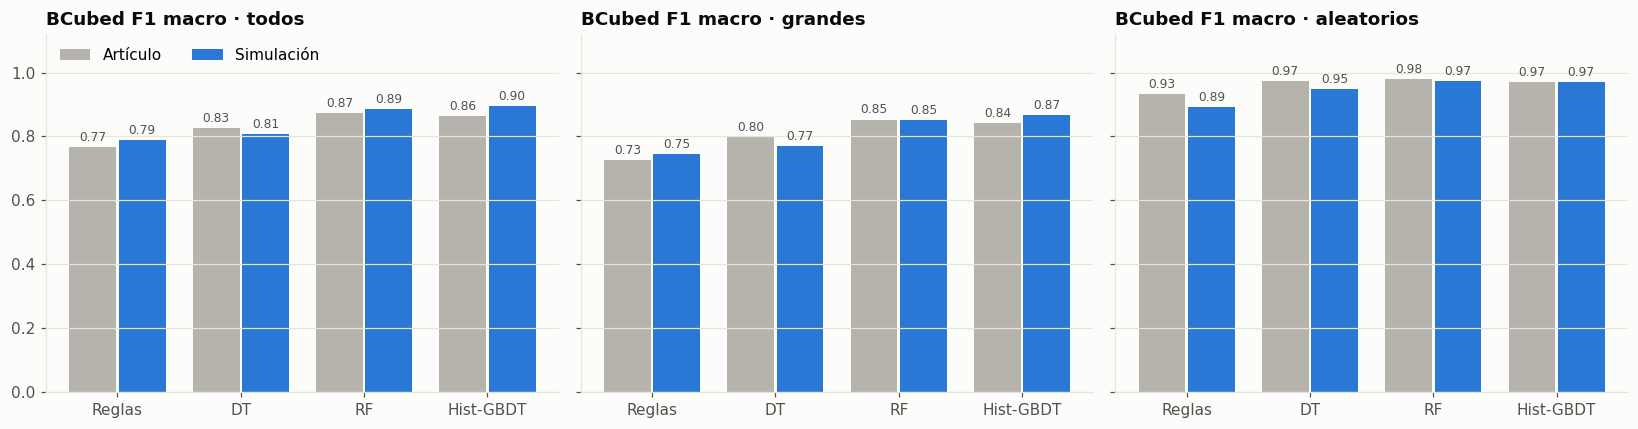

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, subset in zip(axes, ["todos", "grandes", "aleatorios"]):
    s = cmp[cmp.subset == subset]
    PL.paired_bars(ax, [m.replace(" (Milojević)", "").replace("Decision Tree", "DT").replace("Random Forest", "RF")
                        for m in s.modelo], s.macro_b3f_art.values, s.macro_b3f_sim.values, ylim=(0, 1.12))
    ax.set_title(f"BCubed F1 macro · {subset}")
    if ax is not axes[0]:
        ax.get_legend().remove()
fig.tight_layout(); PL.save(fig, "02_comparacion_articulo_vs_simulacion.png")

## 4. Efecto de la proporción de clases (todos los bloques de prueba)

ratio                            {0:1,1:2}  {0:1,1:1}  original  {0:2,1:1}  {0:5,1:1}
algorithm     scoring                                                                
Decision Tree accuracy               0.758      0.771     0.725      0.793      0.809
              average precision      0.758      0.771     0.720      0.793      0.809
Hist-GBDT     accuracy               0.838      0.845     0.845      0.875      0.896
              average precision      0.835      0.845     0.844      0.870      0.893
Random Forest accuracy               0.822      0.835     0.830      0.846      0.877
              average precision      0.834      0.846     0.838      0.867      0.886

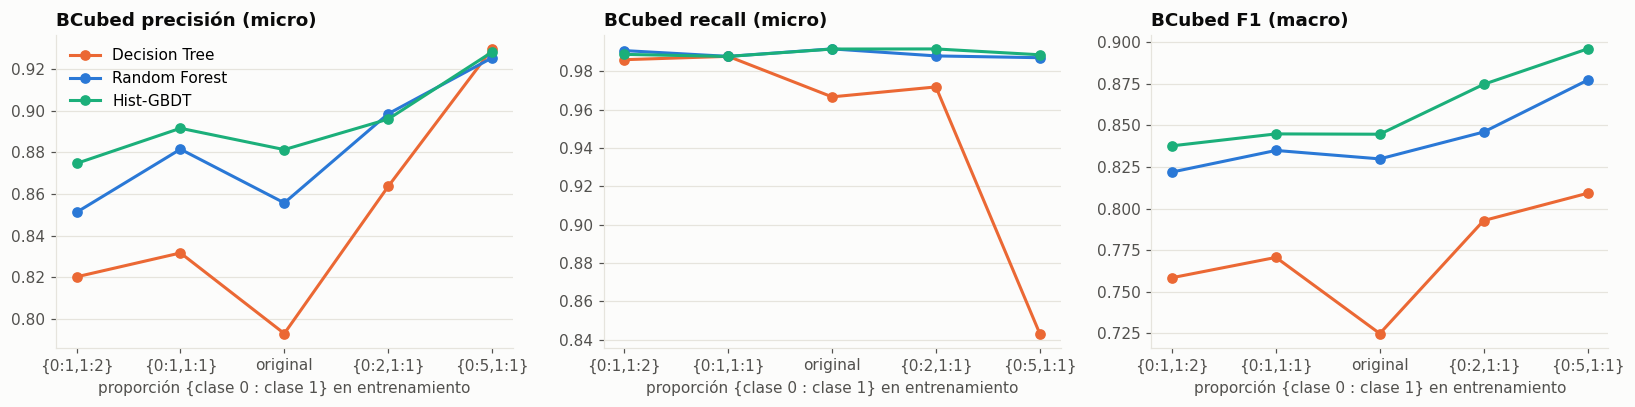

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric, title in zip(axes, ["micro_b3p", "micro_b3r", "macro_b3f"],
                             ["BCubed precisión (micro)", "BCubed recall (micro)", "BCubed F1 (macro)"]):
    PL.ratio_effect(ax, table, "todos", metric, "accuracy")
    ax.set_title(title)
axes[0].legend()
fig.tight_layout(); PL.save(fig, "02_efecto_proporcion_clases.png")
pivot = table[table.subset == "todos"].pivot_table(index=["algorithm", "scoring"], columns="ratio", values="macro_b3f")
pivot = pivot[["{0:1,1:2}", "{0:1,1:1}", "original", "{0:2,1:1}", "{0:5,1:1}"]]
pivot.round(3).to_csv(C.RESULTS / "02_f1_macro_por_proporcion.csv")
pivot.round(3)

## 5. Modelo de referencia fijado *a priori*: Random Forest, accuracy, {0:5,1:1}
Es la configuración que el artículo declara como mejor en general. La usamos para la clasificación de pares (Tabla 5), los bloques grandes (Tabla 7), la interpretación y la extensión del notebook 03, **sin elegirla mirando la prueba**.

In [7]:
ref = next(e for e in evaluated if e["algorithm"] == "Random Forest" and e["ratio"] == "{0:5,1:1}"
           and e["scoring"] == "accuracy")
ref_params = next(r["params"] for r in trained if r["algorithm"] == "Random Forest"
                  and r["ratio"] == "{0:5,1:1}" and r["scoring"] == "accuracy")
json.dump({"algorithm": "Random Forest", "ratio": "{0:5,1:1}", "scoring": "accuracy",
           "params": {k: (float(v) if isinstance(v, float) else v) for k, v in ref_params.items()}},
          open(C.RESULTS / "02_modelo_referencia.json", "w"), indent=2)
print("Hiperparámetros:", ref_params)

rep = ME.pairwise_report(test.y.values, (ref["proba"] >= 0.5).astype(int))
t5 = pd.DataFrame({
    "artículo": [C.ARTICLE_TABLE5[k] for k in ["precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "accuracy"]],
    "simulación": [rep.loc["0", "precision"], rep.loc["0", "recall"], rep.loc["0", "f1-score"],
                   rep.loc["1", "precision"], rep.loc["1", "recall"], rep.loc["1", "f1-score"], rep.loc["accuracy", "precision"]],
}, index=["precisión clase 0", "recall clase 0", "F1 clase 0", "precisión clase 1", "recall clase 1", "F1 clase 1", "accuracy"])
t5.round(3).to_csv(C.RESULTS / "02_tabla5_reporte_pares.csv")
t5.round(3)

Hiperparámetros: {'n_estimators': 30, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'gini'}


,artículo,simulación
precisión clase 0,0.83,0.899
recall clase 0,0.98,0.984
F1 clase 0,0.90,0.939
precisión clase 1,0.97,0.981
recall clase 1,0.77,0.881
F1 clase 1,0.86,0.928
accuracy,0.88,0.934


### Bloques grandes (análogo de la Tabla 7)

In [8]:
bt = ref["blocks"]
large = bt[bt.subset == "test_large"].set_index("block").loc[[b for b, *_ in C.LARGE_BLOCKS]]
art7 = pd.DataFrame(C.ARTICLE_TABLE7, index=["b3p", "b3r", "b3f", "true_clusters", "pred_clusters"]).T
t7 = pd.concat({"artículo": art7, "simulación": large[["b3p", "b3r", "b3f", "true_clusters", "pred_clusters"]]}, axis=1)
t7.round(3).to_csv(C.RESULTS / "02_tabla7_bloques_grandes.csv")
t7.round(3)

artículo                                           simulación                                          
               b3p    b3r    b3f true_clusters pred_clusters        b3p    b3r    b3f true_clusters pred_clusters
binzel.r     0.999  1.000  0.999           2.0           1.0      1.000  1.000  1.000             2             2
lee.j        0.569  0.918  0.702         181.0         110.0      0.411  0.901  0.564            90            23
zhang.y      0.557  0.881  0.682         122.0          72.0      0.618  0.936  0.744            61            28
wang.j       0.641  0.934  0.761         107.0          76.0      0.655  0.903  0.759            54            28
russell.c    1.000  0.984  0.992           9.0          12.0      1.000  1.000  1.000             4             4
chen.y       0.801  0.920  0.856          54.0          21.0      0.704  0.942  0.806            27            16

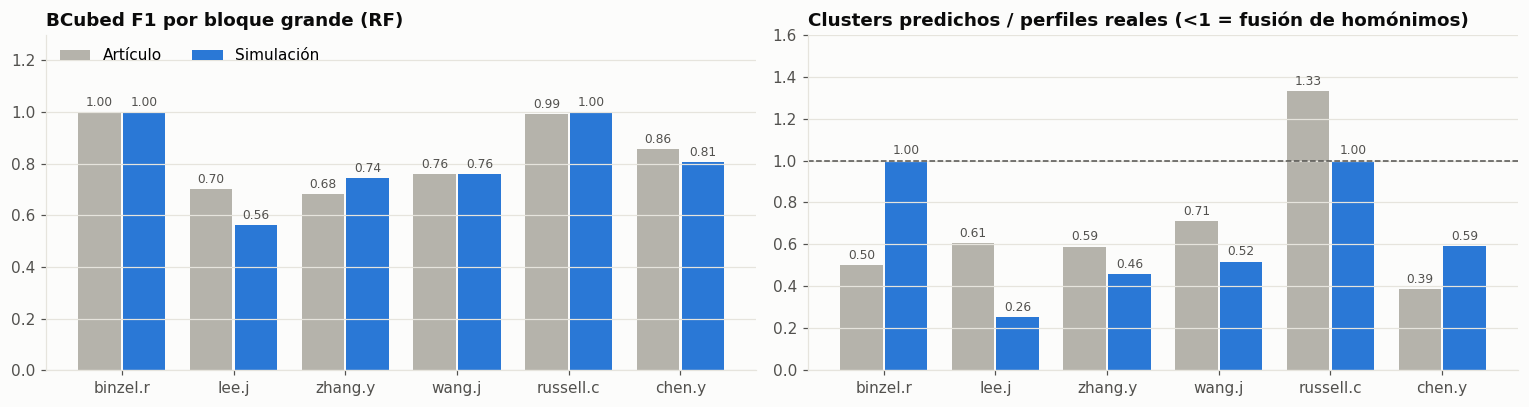

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
PL.paired_bars(axes[0], list(t7.index), t7[("artículo", "b3f")].values, t7[("simulación", "b3f")].values, ylim=(0, 1.3))
axes[0].set_title("BCubed F1 por bloque grande (RF)")
PL.paired_bars(axes[1], list(t7.index), t7[("artículo", "pred_clusters")] / t7[("artículo", "true_clusters")],
               t7[("simulación", "pred_clusters")] / t7[("simulación", "true_clusters")], fmt="{:.2f}", ylim=(0, 1.6))
axes[1].axhline(1, color=PL.MUTED, lw=1, ls="--")
axes[1].set_title("Clusters predichos / perfiles reales (<1 = fusión de homónimos)")
axes[1].get_legend().remove()
fig.tight_layout(); PL.save(fig, "02_bloques_grandes.png")

### Bloques aleatorios (análogo de la Tabla 9)

In [10]:
t9 = bt[bt.subset == "test_random"].set_index("block")[["b3p", "b3r", "b3f", "authorships", "true_clusters", "pred_clusters"]]
t9.round(3).to_csv(C.RESULTS / "02_tabla9_bloques_aleatorios.csv")
print(f"Bloques aleatorios resueltos perfectamente (F1 = 1): {(t9.b3f > 0.9999).sum()} de {len(t9)} "
      f"(artículo: 20 de 33)")
t9.sort_values("b3f").head(8).round(3)

Bloques aleatorios resueltos perfectamente (F1 = 1): 22 de 33 (artículo: 20 de 33)


,b3p,b3r,b3f,authorships,true_clusters,pred_clusters
block,,,,,,
vincent.m,0.668,1.000,0.801,36,6,3
ribeiro.a,0.756,0.977,0.853,75,10,3
rovira.m,0.808,1.000,0.894,65,2,1
vargas.c,0.863,1.000,0.927,13,5,4
miller.v,0.915,0.939,0.927,22,6,6
adam.m,0.886,1.000,0.940,16,6,5
klein.u,0.909,0.992,0.949,228,5,3
moreno.c,1.000,0.937,0.967,21,3,4


## 6. ¿Qué evidencia usa el modelo?
Importancia de variables del Random Forest agregada por grupo de la Tabla 2 y explicaciones locales tipo LIME para tres pares del bloque `chen.y` (el mismo bloque que usa el artículo en las Tablas 10–13).

Nombre            0.276
Coautores         0.207
Año               0.196
Afiliación        0.160
Título/resumen    0.107
Bloque            0.044
Palabras clave    0.007
Revista           0.003
dtype: float64

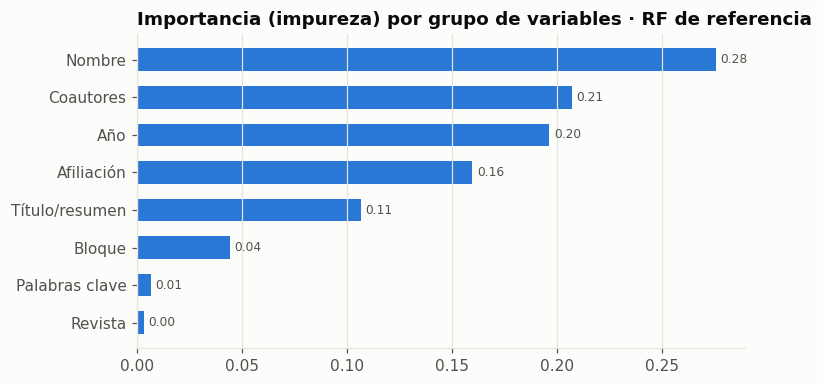

In [11]:
model = ref["model"]
imp = pd.Series(model.feature_importances_, index=F.FEATURES)
grp = pd.Series({g: imp[fs].sum() for g, fs in F.FEATURE_GROUPS.items()}).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(grp.index, grp.values, color=PL.PALETTE[0], height=0.6)
for i, v in enumerate(grp.values):
    ax.annotate(f"{v:.2f}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8, color=PL.MUTED)
ax.set_title("Importancia (impureza) por grupo de variables · RF de referencia"); ax.grid(axis="y", visible=False)
fig.tight_layout(); PL.save(fig, "02_importancia_variables.png")
imp.sort_values(ascending=False).round(3).to_csv(C.RESULTS / "02_importancia_variables.csv", header=["importancia"])
grp.sort_values(ascending=False).round(3)


Mismo autor, nombre ambiguo (acierto) · P(clase 1) = 0.96
                                                            autoría 1                                             autoría 2
name                                                         Chen, Y.                                              Chen, Y.
affiliation  Department of Physics, University of Wuhan, Wuhan, China  School of Physics, University of Wuhan, Wuhan, China
year                                                             2018                                                  2014
journal             Monthly Notices of the Royal Astronomical Society                               Physical Review Letters
coauthors                                young.b; campbell.c; russo.a                            young.b; gray.l; smirnov.b

Homónimos con el mismo nombre de pila (acierto) · P(clase 1) = 0.08
                                                               autoría 1                                                    auto

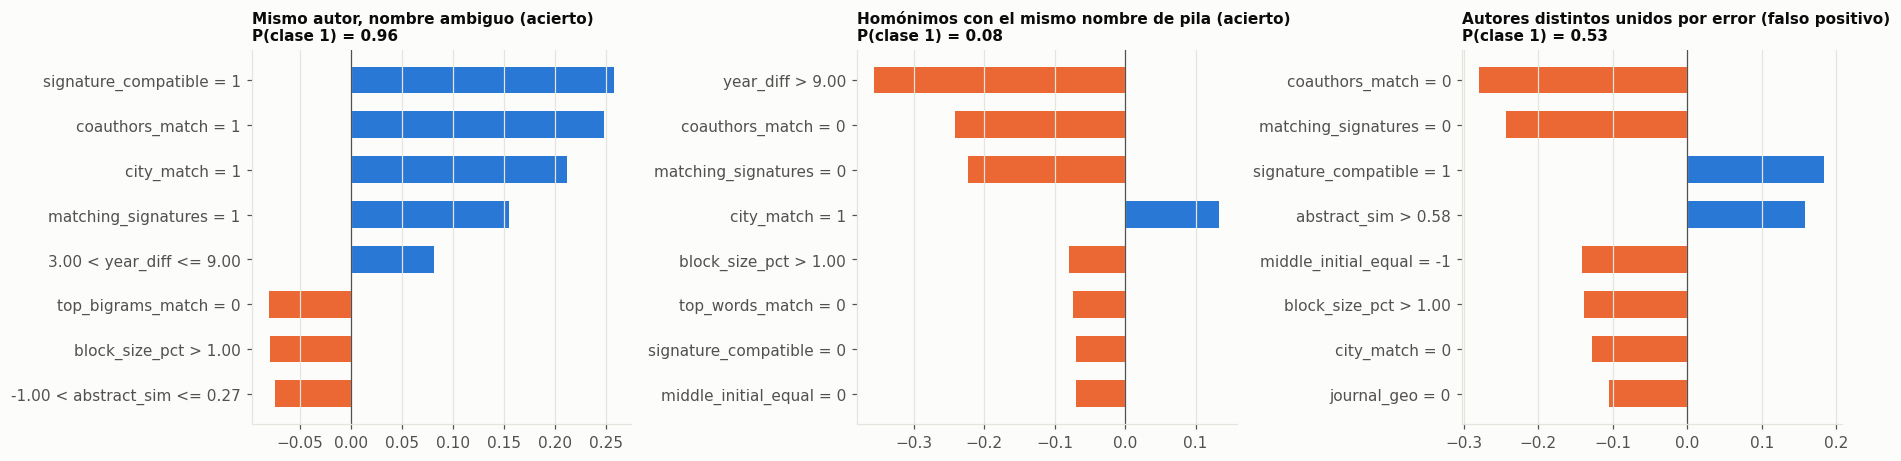

In [12]:
chen = test[test.block == "chen.y"].copy()
chen["p"] = ref["proba"][chen.index]
rng = np.random.default_rng(C.SEED)
cases = {
    "Mismo autor, nombre ambiguo (acierto)": chen[(chen.y == 1) & (chen.first_name_equal == -2) & (chen.p > 0.8)],
    "Homónimos con el mismo nombre de pila (acierto)": chen[(chen.y == 0) & (chen.first_name_equal == 1) & (chen.p < 0.2)],
    "Autores distintos unidos por error (falso positivo)": chen[(chen.y == 0) & (chen.p >= 0.5)],
}
X_bg = train[F.FEATURES].to_numpy(np.float32)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
lime_rows = []
for ax, (title, cand) in zip(axes, cases.items()):
    row = cand.iloc[int(rng.integers(0, len(cand)))]
    tab, prob = EX.explain_instance(model, row[F.FEATURES].to_numpy(np.float32), X_bg, F.FEATURES, n_top=8, seed=1)
    a, b = df.loc[int(row.i)], df.loc[int(row.j)]
    print(f"\n{title} · P(clase 1) = {prob:.2f}")
    print(pd.DataFrame({"autoría 1": a[["name", "affiliation", "year", "journal", "coauthors"]],
                        "autoría 2": b[["name", "affiliation", "year", "journal", "coauthors"]]}).to_string(max_colwidth=60))
    t = tab.iloc[::-1]
    ax.barh(t.condicion, t.peso, color=[PL.PALETTE[0] if v > 0 else PL.PALETTE[1] for v in t.peso], height=0.6)
    ax.axvline(0, color=PL.MUTED, lw=0.8)
    ax.set_title(f"{title}\nP(clase 1) = {prob:.2f}", fontsize=10); ax.grid(axis="y", visible=False)
    lime_rows += [{"caso": title, "prob": prob, **r} for r in tab.to_dict("records")]
fig.tight_layout(); PL.save(fig, "02_explicaciones_lime.png")
pd.DataFrame(lime_rows).round(3).to_csv(C.RESULTS / "02_explicaciones_lime.csv", index=False)

## 7. ¿Qué patrones del artículo se reproducen?
Se verifican automáticamente las afirmaciones cualitativas del artículo sobre los resultados simulados.

In [13]:
todos = table[table.subset == "todos"]
bt_ = best.set_index(["subset", "modelo"])
rf = todos[(todos.algorithm == "Random Forest") & (todos.scoring == "accuracy")].set_index("ratio")
best_ratio = todos.loc[todos.groupby("algorithm").macro_b3f.idxmax()].set_index("algorithm").ratio
rng_ratio = todos.groupby(["algorithm", "scoring"]).macro_b3f.agg(lambda s: s.max() - s.min()).mean()
rng_scoring = todos.groupby(["algorithm", "ratio"]).macro_b3f.agg(lambda s: s.max() - s.min()).mean()
checks = [
    ("Los 3 modelos de ML superan a la regla de Milojević (F1 macro, todos)",
     all(bt_.loc[("todos", m), "macro_b3f"] > bt_.loc[("todos", "Reglas (Milojević)"), "macro_b3f"]
         for m in ["Decision Tree", "Random Forest", "Hist-GBDT"])),
    ("Random Forest es el mejor algoritmo (F1 macro, todos)",
     bt_.loc["todos"].drop("Reglas (Milojević)").macro_b3f.idxmax() == "Random Forest"),
    ("{0:5,1:1} es la mejor proporción para los 3 algoritmos (todos)", bool((best_ratio == "{0:5,1:1}").all())),
    ("La proporción pesa más que la función objetivo", rng_ratio > rng_scoring),
    ("Más clase 1 en entrenamiento => más recall y menos precisión BCubed (RF)",
     rf.loc["{0:1,1:2}", "micro_b3r"] >= rf.loc["{0:5,1:1}", "micro_b3r"] and
     rf.loc["{0:1,1:2}", "micro_b3p"] < rf.loc["{0:5,1:1}", "micro_b3p"]),
    ("Los bloques grandes son más difíciles que los aleatorios (RF)",
     bt_.loc[("grandes", "Random Forest"), "macro_b3f"] < bt_.loc[("aleatorios", "Random Forest"), "macro_b3f"]),
    ("En bloques grandes la regla tiene precisión alta y recall bajo",
     bt_.loc[("grandes", "Reglas (Milojević)"), "macro_b3p"] > bt_.loc[("grandes", "Reglas (Milojević)"), "macro_b3r"]),
    ("En bloques grandes el RF predice menos clusters que perfiles reales (fusiona homónimos)",
     bool((large.pred_clusters < large.true_clusters)[["lee.j", "zhang.y", "wang.j", "chen.y"]].all())),
    ("Pares: precisión clase 1 > clase 0 y recall clase 0 > clase 1 (Tabla 5)",
     rep.loc["1", "precision"] > rep.loc["0", "precision"] and rep.loc["0", "recall"] > rep.loc["1", "recall"]),
]
pat = pd.DataFrame(checks, columns=["patrón del artículo", "¿se reproduce?"])
pat.to_csv(C.RESULTS / "02_patrones_reproducidos.csv", index=False)
print(f"{pat['¿se reproduce?'].sum()} de {len(pat)} patrones reproducidos")
pat

7 de 9 patrones reproducidos


,patrón del artículo,¿se reproduce?
0,Los 3 modelos de ML superan a la regla de Milo...,True
1,"Random Forest es el mejor algoritmo (F1 macro,...",False
2,"{0:5,1:1} es la mejor proporción para los 3 al...",True
3,La proporción pesa más que la función objetivo,True
4,Más clase 1 en entrenamiento => más recall y m...,True
5,Los bloques grandes son más difíciles que los ...,True
6,En bloques grandes la regla tiene precisión al...,False
7,En bloques grandes el RF predice menos cluster...,True
8,Pares: precisión clase 1 > clase 0 y recall cl...,True
